<class 'pandas.DataFrame'>
DatetimeIndex: 2959 entries, 2015-01-02 to 2026-10-08
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       2959 non-null   float64
 1   High       2959 non-null   float64
 2   Low        2959 non-null   float64
 3   Close      2959 non-null   float64
 4   Adj Close  2959 non-null   float64
 5   Volume     2959 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 161.8 KB


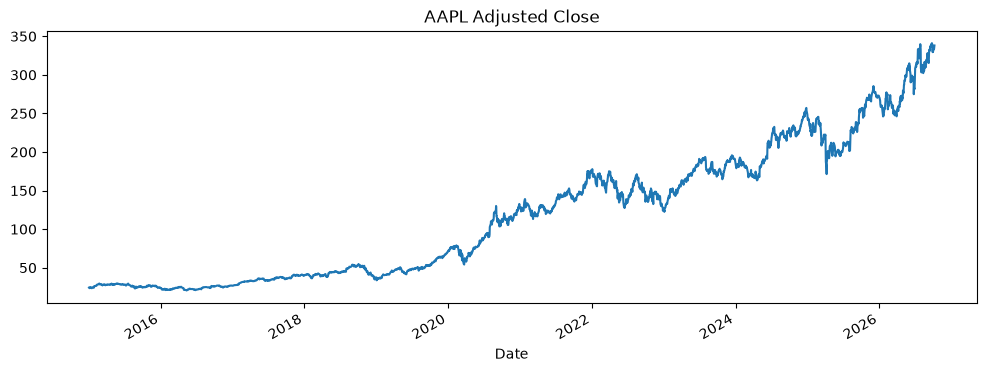

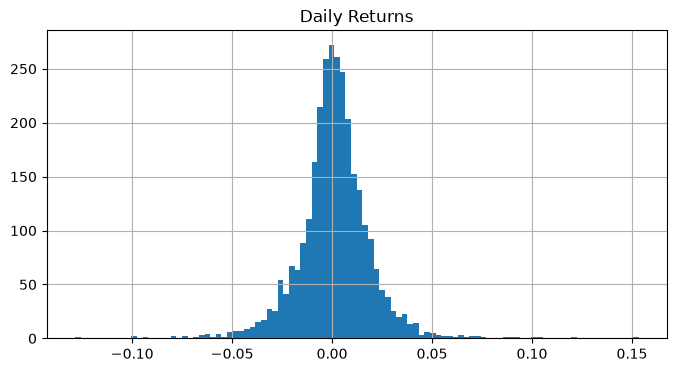

Mean: 0.0010553285028382868 | Std: 0.018071354040223492


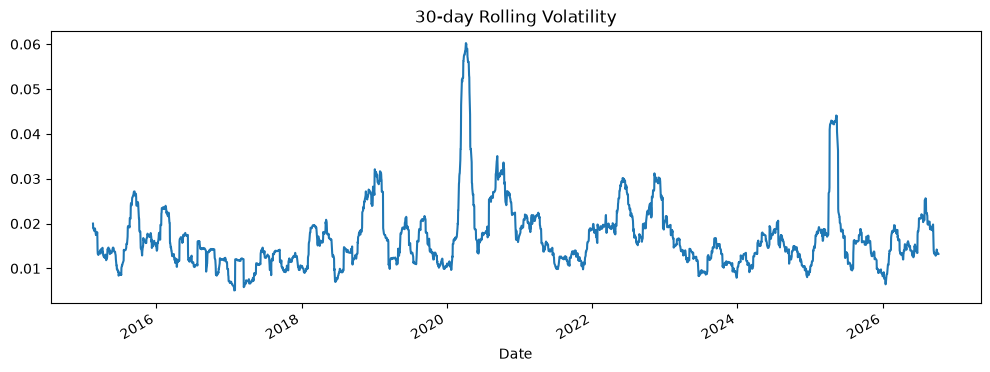

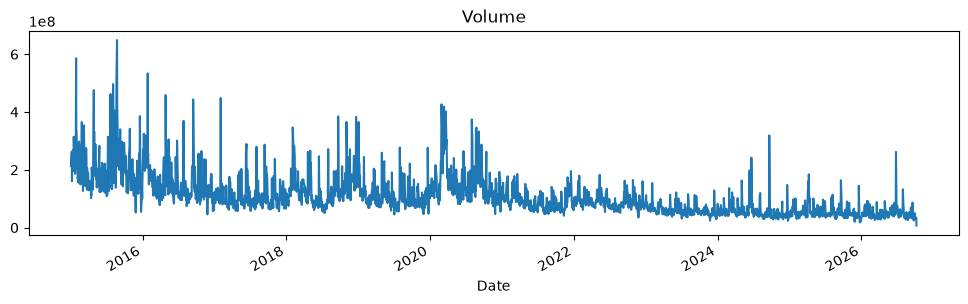

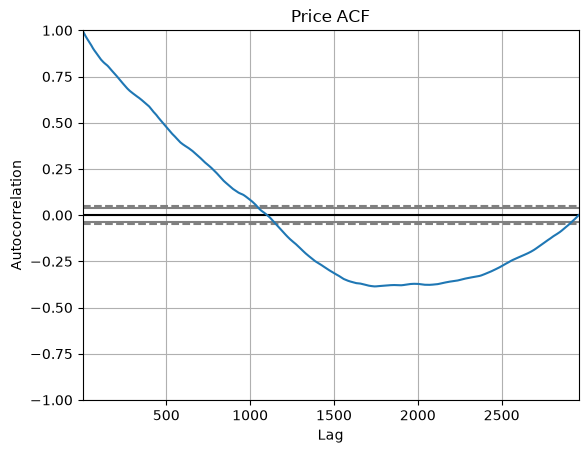

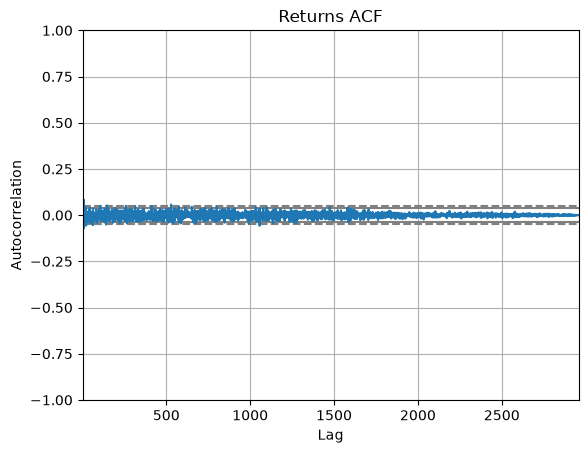

In [1]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import download_stock_data
from src.data_cleaning import clean_stock_data

raw = download_stock_data("AAPL")
df = clean_stock_data(raw, "AAPL")

df.info()
df.describe()

# 1. Price over time
df["Adj Close"].plot(figsize=(12, 4), title="AAPL Adjusted Close")
plt.show()

# 2. Daily returns distribution
returns = df["Adj Close"].pct_change().dropna()
returns.hist(bins=100, figsize=(8, 4))
plt.title("Daily Returns")
plt.show()
print("Mean:", returns.mean(), "| Std:", returns.std())

# 3. Rolling volatility
returns.rolling(30).std().plot(figsize=(12, 4), title="30-day Rolling Volatility")
plt.show()

# 4. Volume over time
df["Volume"].plot(figsize=(12, 3), title="Volume")
plt.show()

# 5. Check stationarity intuition: price vs returns autocorrelation
from pandas.plotting import autocorrelation_plot
autocorrelation_plot(df["Adj Close"]); plt.title("Price ACF"); plt.show()
autocorrelation_plot(returns); plt.title("Returns ACF"); plt.show()